## Limitations
- Data are at the level of games, not players: no information about countries, teams or gender.
- 2024 is incomplete.
- Prize money is in nominal USD and is not industry revenue.
- The analysis is descriptive; explanations (pandemic, mega-events, mobile games) are hypotheses, not tested statistically.

## 6. Prize money per player by genre
`TotalEarnings / TotalPlayers` per game, summarised by genre (median). This is a rough measure: it includes very small payouts and is not adjusted for inflation.

In [56]:
gen["EarnPerPlayer"] = gen["TotalEarnings"] / gen["TotalPlayers"].replace(0, pd.NA)
by_genre = gen.groupby("Genre").agg(
    games=("Game", "count"),
    total=("TotalEarnings", "sum"),
    median_per_player=("EarnPerPlayer", "median"),
).sort_values("total", ascending=False)
print(by_genre.head(8).round(0))

                                 games        total median_per_player
Genre                                                                
Multiplayer Online Battle Arena     29  643829102.0       3663.024005
First-Person Shooter               138  483596198.0            3125.0
Battle Royale                       17  390379255.0      10317.113757
Strategy                            68  135819162.0       2047.371981
Sports                              98  106413829.0          6537.076
Collectible Card Game               17   51485118.0       2247.934354
Fighting Game                      189   39733007.0        247.443243
Racing                              66   18528691.0       2654.618585


Battle Royale and Sports have the highest median prize per player; fighting games have many titles but very small payouts per player.

## 5. Top games and genres by year
The three largest games per year, and the share of the main genres in each year's prize money.

In [57]:
hist["Year"] = hist["Date"].dt.year

# Top-3 games per year with their share
for year in range(2017, 2025):
    g = hist[hist["Year"] == year].groupby("Game")["Earnings"].sum().sort_values(ascending=False)
    top3 = (g.head(3) / g.sum()).round(2)
    print(year, {k: float(v) for k, v in top3.items()})

# Genre share of prize money by year
h = hist.merge(gen[["Game", "Genre"]], on="Game", how="left")
genre_year = h.groupby(["Year", "Genre"])["Earnings"].sum().unstack(fill_value=0)
genre_share = genre_year.div(genre_year.sum(axis=1), axis=0).round(2)
top_genres = genre_year.sum().sort_values(ascending=False).head(6).index
print(genre_share.loc[2017:, top_genres])

2017 {'Dota 2': 0.31, 'Counter-Strike: Global Offensive': 0.16, 'League of Legends': 0.1}
2018 {'Dota 2': 0.24, 'Counter-Strike: Global Offensive': 0.13, 'Fortnite': 0.11}
2019 {'Fortnite': 0.31, 'Dota 2': 0.18, 'Counter-Strike: Global Offensive': 0.09}
2020 {'Fortnite': 0.12, 'Counter-Strike: Global Offensive': 0.11, 'Arena of Valor': 0.07}
2021 {'Dota 2': 0.18, 'Fortnite': 0.09, "PLAYERUNKNOWN'S BATTLEGROUNDS Mobile": 0.08}
2022 {'Dota 2': 0.13, 'Arena of Valor': 0.11, "PLAYERUNKNOWN'S BATTLEGROUNDS Mobile": 0.09}
2023 {'Dota 2': 0.13, "PLAYERUNKNOWN'S BATTLEGROUNDS Mobile": 0.09, 'Fortnite': 0.08}
2024 {'Dota 2': 0.13, 'Counter-Strike 2': 0.1, 'Fortnite': 0.08}
Genre  Multiplayer Online Battle Arena  First-Person Shooter  Battle Royale  \
Year                                                                          
2017                              0.49                  0.29           0.02   
2018                              0.41                  0.26           0.17   
2019       

Fortnite took 31% of prize money in 2019, which explains the 2019 peak. After 2020 no single game dominates and mobile titles appear in the top 3. MOBA, first-person shooters and Battle Royale together still hold about 78–80% of prize money.

## 4. Concentration index (HHI) and the role of Dota 2
HHI is the sum of squared market shares of all games in a year; values closer to 1 mean higher concentration. The table also shows the number of active games and Dota 2's share.

In [58]:
# 1. Number of games with prize money each year
active = hist[hist["Earnings"] > 0].groupby("Year")["Game"].nunique()

# 2. Dota 2 share of each year's prize money
dota = hist[hist["Game"] == "Dota 2"].groupby("Year")["Earnings"].sum()
dota_share = (dota / by_year).dropna()

# 3. Herfindahl index (HHI): sum of squared market shares; closer to 1 means higher concentration
hhi_rows = []
for year, g in hist.groupby("Year"):
    s = g.groupby("Game")["Earnings"].sum()
    shares = s / s.sum()
    hhi_rows.append((year, (shares ** 2).sum()))
hhi = pd.Series(dict(hhi_rows))

summary = pd.DataFrame({
    "ActiveGames": active,
    "DotaShare": dota_share.round(2),
    "HHI": hhi.round(3),
})
print(summary.loc[2012:])

      ActiveGames  DotaShare    HHI
2012           63       0.14  0.193
2013           65       0.20  0.153
2014           70       0.43  0.247
2015          102       0.45  0.238
2016          121       0.37  0.186
2017          140       0.31  0.141
2018          165       0.24  0.105
2019          197       0.18  0.148
2020          226       0.07  0.053
2021          208       0.18  0.071
2022          170       0.13  0.057
2023          127       0.13  0.056
2024          102       0.13  0.055


HHI fell from 0.148 in 2019 to 0.053 in 2020, and stayed low (about 0.055–0.07) afterwards. Dota 2's share dropped in 2020 and recovered in 2021, but concentration did not return to its previous level.

## 3. Visualisation
Total prize money by year and the share of the top-5 games in each year.

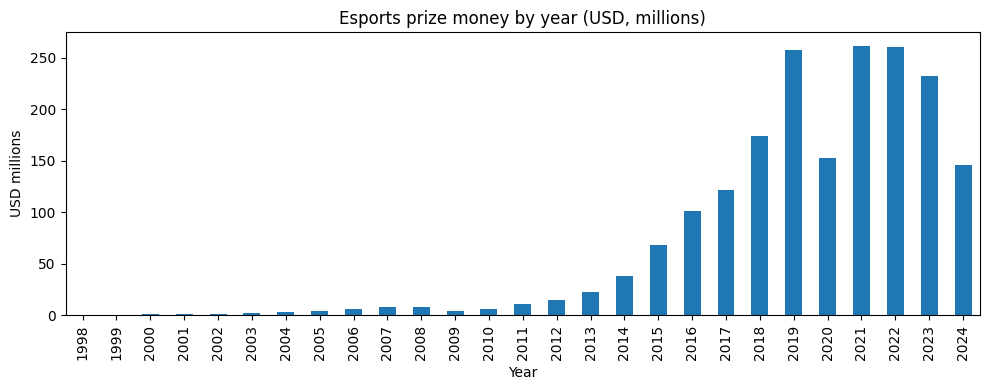

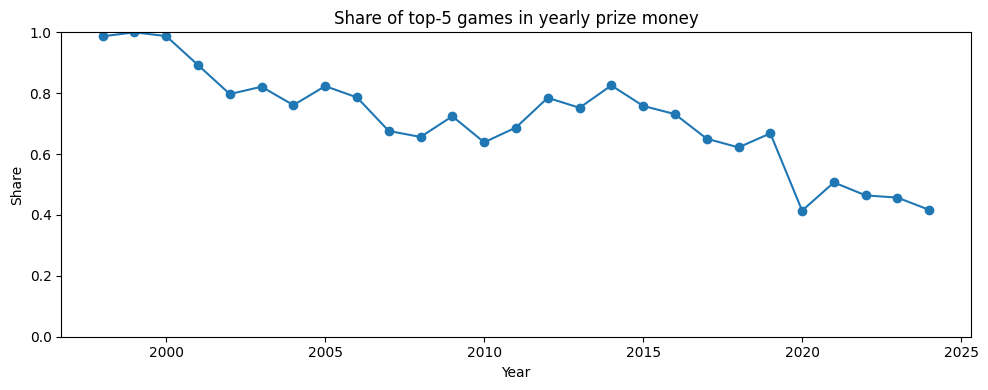

      Top5Share
Year           
1998       0.99
1999       1.00
2000       0.99
2001       0.89
2002       0.80
2003       0.82
2004       0.76
2005       0.82
2006       0.79
2007       0.68
2008       0.66
2009       0.72
2010       0.64
2011       0.69
2012       0.78
2013       0.75
2014       0.83
2015       0.76
2016       0.73
2017       0.65
2018       0.62
2019       0.67
2020       0.41
2021       0.51
2022       0.46
2023       0.46
2024       0.42


In [59]:
import matplotlib.pyplot as plt

# 1. Chart: prize money by year
by_year_m = by_year / 1e6
plt.figure(figsize=(10, 4))
by_year_m.plot(kind="bar")
plt.title("Esports prize money by year (USD, millions)")
plt.ylabel("USD millions")
plt.tight_layout()
plt.savefig("fig1_prize_by_year.png", dpi=150)
plt.show()

# 2. Share of top-5 games in each year's prize money
rows = []
for year, g in hist.groupby("Year"):
    s = g.groupby("Game")["Earnings"].sum().sort_values(ascending=False)
    rows.append((year, s.head(5).sum() / s.sum()))
conc = pd.DataFrame(rows, columns=["Year", "Top5Share"]).set_index("Year")

plt.figure(figsize=(10, 4))
conc["Top5Share"].plot(marker="o")
plt.title("Share of top-5 games in yearly prize money")
plt.ylabel("Share")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("fig2_top5_share.png", dpi=150)
plt.show()
print(conc.round(2))

Prize money grew strongly until 2019 and dropped in 2020. The share of the top-5 games fell from about 99% in 1998–2000 to about 40–50% after 2020.

## 2. Concentration of prize money and totals by year
Share of the 10 largest games in total prize money, and total prize money per year.

In [60]:
# 1. Share of top-10 games in total prize money
gen = gen.sort_values("TotalEarnings", ascending=False)
share = gen["TotalEarnings"] / gen["TotalEarnings"].sum()
print("Share of top-10 games:", round(share.head(10).sum(), 3))
print(gen[["Game", "Genre", "TotalEarnings"]].head(10))

# 2. Prize money by year
hist["Year"] = hist["Date"].dt.year
by_year = hist.groupby("Year")["Earnings"].sum()
print(by_year)

Share of top-10 games: 0.64
                                     Game                            Genre  \
215                                Dota 2  Multiplayer Online Battle Arena   
637                              Fortnite                    Battle Royale   
116      Counter-Strike: Global Offensive             First-Person Shooter   
221                     League of Legends  Multiplayer Online Battle Arena   
206                        Arena of Valor  Multiplayer Online Battle Arena   
641  PLAYERUNKNOWN'S BATTLEGROUNDS Mobile                    Battle Royale   
642         PLAYERUNKNOWN’S BATTLEGROUNDS                    Battle Royale   
169                     Rainbow Six Siege             First-Person Shooter   
43                           StarCraft II                         Strategy   
590                         Rocket League                           Sports   

     TotalEarnings  
215   3.604612e+08  
637   1.910127e+08  
116   1.624897e+08  
221   1.135960e+08  
206   9.

The 10 largest games (about 1.5% of all games) earn 64% of all prize money. Dota 2 alone earns about one fifth. Yearly prize money grew until 2019, fell in 2020, and recovered in 2021. 2024 is incomplete (data until October).

## 1. Loading the data
Load both files and check their size and the covered period.

In [61]:
# 1. Share of top-10 games in total prize money
gen = gen.sort_values("TotalEarnings", ascending=False)
share = gen["TotalEarnings"] / gen["TotalEarnings"].sum()
print("Share of top-10 games:", round(share.head(10).sum(), 3))
print(gen[["Game", "Genre", "TotalEarnings"]].head(10))

# 2. Prize money by year
hist["Year"] = hist["Date"].dt.year
by_year = hist.groupby("Year")["Earnings"].sum()
print(by_year)

Share of top-10 games: 0.64
                                     Game                            Genre  \
215                                Dota 2  Multiplayer Online Battle Arena   
637                              Fortnite                    Battle Royale   
116      Counter-Strike: Global Offensive             First-Person Shooter   
221                     League of Legends  Multiplayer Online Battle Arena   
206                        Arena of Valor  Multiplayer Online Battle Arena   
641  PLAYERUNKNOWN'S BATTLEGROUNDS Mobile                    Battle Royale   
642         PLAYERUNKNOWN’S BATTLEGROUNDS                    Battle Royale   
169                     Rainbow Six Siege             First-Person Shooter   
43                           StarCraft II                         Strategy   
590                         Rocket League                           Sports   

     TotalEarnings  
215   3.604612e+08  
637   1.910127e+08  
116   1.624897e+08  
221   1.135960e+08  
206   9.

The dataset has 669 games and 10,239 monthly records, from January 1998 to October 2024.

# Esports Prize Money: Market Concentration, 1998–2024

Exploratory analysis of how esports prize money is distributed across games and genres, and how this changed over time.

## Research questions
1. How concentrated is prize money among a few games?
2. How did concentration change between 1998 and 2024?
3. What happened in 2020, and did the market return to its previous structure?
4. Which genres capture most of the prize money?

## Data
Kaggle dataset `rankirsh/esports-earnings`: `GeneralEsportData.csv` (one row per game) and `HistoricalEsportData.csv` (monthly records per game).

In [62]:
import pandas as pd

gen = pd.read_csv("/GeneralEsportData.csv")
hist = pd.read_csv("/HistoricalEsportData.csv", parse_dates=["Date"])

print(gen.shape, hist.shape)
print(hist["Date"].min(), hist["Date"].max())
gen.head()

(669, 8) (10239, 5)
1998-01-01 00:00:00 2024-10-01 00:00:00


,Game,ReleaseDate,Genre,TotalEarnings,OfflineEarnings,PercentOffline,TotalPlayers,TotalTournaments
0,Age of Empires,1997,Strategy,736284.75,522378.17,0.709478,624,341
1,Age of Empires II,1999,Strategy,3898508.73,1361409.22,0.349213,2256,1939
2,Age of Empires III,2005,Strategy,122256.72,44472.60,0.363764,172,179
3,Age of Empires IV,2021,Strategy,1190813.44,439117.93,0.368755,643,423
4,Age of Empires Online,2011,Strategy,11462.98,775.00,0.067609,52,68
